In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error


Fitted RF_SBP
Fitted RF_DBP
fitted both models for feature ppg_mean_sys_peak with index 1
fitted both models for feature ppg_mean_dia_start with index 2
fitted both models for feature ppg_mean_dia_peak with index 3
fitted both models for feature ppg_mean_skew with index 4
fitted both models for feature ppg_mean_w with index 5
fitted both models for feature ppg_mean_y with index 6
fitted both models for feature ppg_mean_z with index 7
fitted both models for feature ppg_mean_a with index 8
fitted both models for feature ppg_mean_b with index 9
fitted both models for feature ppg_mean_c with index 10
fitted both models for feature ppg_mean_d with index 11
fitted both models for feature ppg_mean_e with index 12
fitted both models for feature ppg_mean_bd with index 13
fitted both models for feature ppg_mean_scoo with index 14
fitted both models for feature ppg_mean_sc with index 15
fitted both models for feature ppg_mean_bcda with index 16
fitted both models for feature ppg_mean_cw with inde

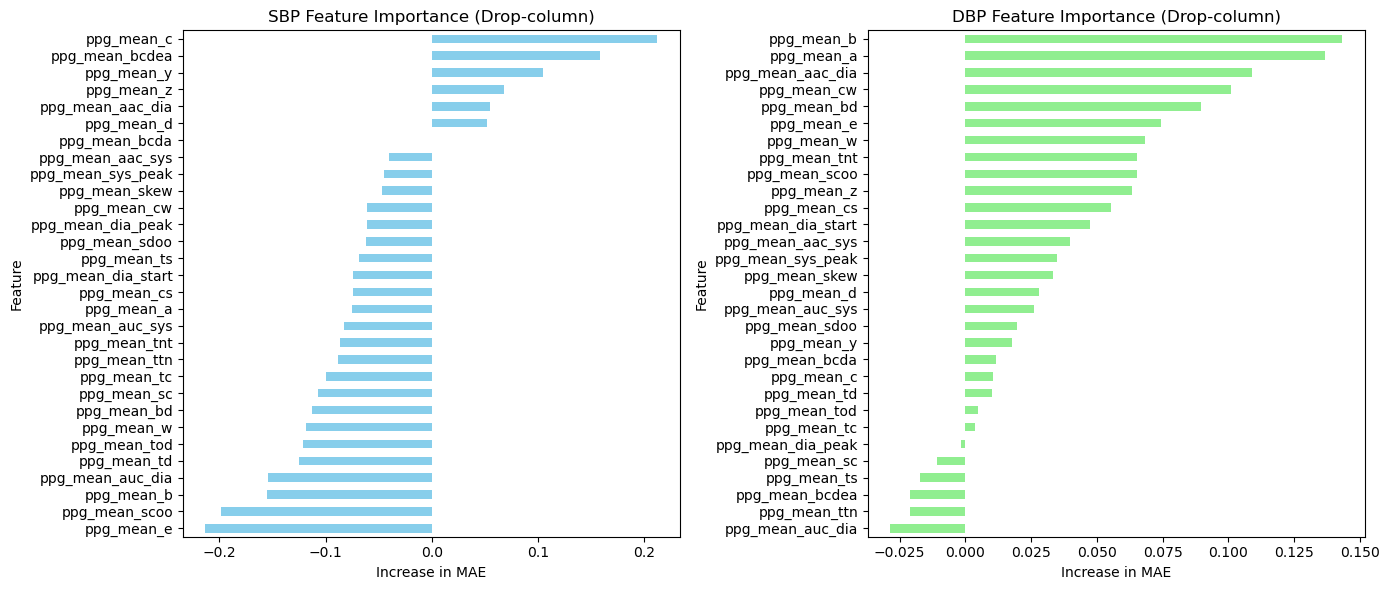

In [ ]:
df = pd.read_csv('ABP_PPG_features.csv')

y_SBP = df['SBP']
y_DBP = df['DBP']

exclude_cols = [
    "data_ID", "struct", "SBP", "DBP",
    "ppg_mean_mean_sbp", "ppg_mean_mean_dbp",
    "ppg_mean_sbp_class", "ppg_mean_dbp_class"
]

feature_cols = [c for c in df.columns if c not in exclude_cols]

X = df[feature_cols]


'''
X_train: Contains 80% of the dataset rows/samples used as input to train model
y_SBP_train: Contains 80% of the same dataset rows/samples from X_train used as target/output of the trained model
X_val: Contains 20% of the dataset rows/samples used as input to the trained model to predict
y_SBP_val: Contains 20% of the same dataset rows/samples used in X_val used as the true value the trained model needs to predict
'''
X_train, X_val, y_SBP_train, y_SBP_val = train_test_split(
    X, y_SBP, test_size=0.2, random_state=42
)

_, _, y_DBP_train, y_DBP_val = train_test_split(
    X, y_DBP, test_size=0.2, random_state=42
)


RF_SBP = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


RF_DBP = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# baseline error: the error of the model trained on all features
RF_SBP.fit(X_train,y_SBP_train)
baseline_error_SBP = mean_absolute_error(y_SBP_val, RF_SBP.predict(X_val))
print('Fitted RF_SBP')
RF_DBP.fit(X_train,y_DBP_train)
baseline_error_DBP = mean_absolute_error(y_DBP_val, RF_DBP.predict(X_val))
print('Fitted RF_DBP')

feature_importances_SBP = {}
feature_importances_DBP = {}
i = 0
for f in X_train.columns:
    X_train_drop = X_train.drop(columns=[f])
    X_val_drop = X_val.drop(columns=[f])

    RF_SBP.fit(X_train_drop,y_SBP_train)
    RF_DBP.fit(X_train_drop,y_DBP_train)
    error_drop_SDP = mean_absolute_error(y_SBP_val, RF_SBP.predict(X_val_drop))
    error_drop_DBP = mean_absolute_error(y_DBP_val, RF_DBP.predict(X_val_drop))
    
    feature_importances_SBP[f] = error_drop_SDP - baseline_error_SBP
    feature_importances_DBP[f] = error_drop_DBP - baseline_error_DBP
    i+=1
    print(f'fitted both models for feature {f} with index {i}')


sbp_importance = pd.Series(feature_importances_SBP).sort_values(ascending=False)
dbp_importance = pd.Series(feature_importances_DBP).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

sbp_importance.sort_values(ascending=True).plot.barh(ax=ax[0], color="skyblue")
ax[0].set_title("SBP Feature Importance (Drop-column)")
ax[0].set_xlabel("Increase in MAE")
ax[0].set_ylabel("Feature")

dbp_importance.sort_values(ascending=True).plot.barh(ax=ax[1], color="lightgreen")
ax[1].set_title("DBP Feature Importance (Drop-column)")
ax[1].set_xlabel("Increase in MAE")
ax[1].set_ylabel("Feature")

plt.tight_layout()
plt.savefig("feature_importance_drop_column.png", dpi=300)
plt.show()


